Привет! меня зовут Люман Аблаев. Сегодня я проверю твой проект.
<br> Дальнейшее общение будет происходить на "ты" если это не вызывает никаких проблем.
<br> Желательно реагировать на каждый мой комментарий ('исправил', 'не понятно как исправить ошибку', ...)
<br> Пожалуйста, не удаляй комментарии ревьюера, так как они повышают качество повторного ревью.

Комментарии будут в <font color='green'>зеленой</font>, <font color='blue'>синей</font> или <font color='red'>красной</font> рамках:чйв


<div class="alert alert-block alert-success">
<b>Успех:</b> Если все сделано отлично
</div>

<div class="alert alert-block alert-info">
<b>Совет: </b> Если можно немного улучшить
</div>

<div class="alert alert-block alert-danger">
<b>Ошибка:</b> Если требуются исправления. Работа не может быть принята с красными комментариями.
</div>

-------------------

Будет очень хорошо, если ты будешь помечать свои действия следующим образом:
<div class="alert alert-block alert-warning">
<b>Комментарий студента:</b> ..
</div>
<div class="alert alert-block alert-warning">
<b>Изменения:</b> Были внесены следующие изменения ...
</div>

<font color='orange' style='font-size:24px; font-weight:bold'>Полезные ссылки</font>
* Очень интересная и полезная статья: https://dyakonov.org/2021/05/27/imbalance/

<font color='orange' style='font-size:24px; font-weight:bold'>Общее впечатление</font>
* Спасибо за  качественную работу, мне она очень понравилась
- Я оставил некоторые советы, надеюсь они будут полезными или интересными.
- Есть небольшие недочеты, которые нужно поправить и обновить вычисления
- Жду обновленную работу

<font color='orange' style='font-size:24px; font-weight:bold'>Общее впечатление[2]</font>

- Недочеты исправлены - работа полностью корректна
- Рад был быть полезен. Удачи в дальнейшем обучении!

<h1>Содержание<span class="tocSkip"></span></h1>
<div class="toc"><ul class="toc-item"><li><span><a href="#Подготовка-данных" data-toc-modified-id="Подготовка-данных-1"><span class="toc-item-num">1&nbsp;&nbsp;</span>Подготовка данных</a></span></li><li><span><a href="#Исследование-задачи" data-toc-modified-id="Исследование-задачи-2"><span class="toc-item-num">2&nbsp;&nbsp;</span>Исследование задачи</a></span></li><li><span><a href="#Борьба-с-дисбалансом" data-toc-modified-id="Борьба-с-дисбалансом-3"><span class="toc-item-num">3&nbsp;&nbsp;</span>Борьба с дисбалансом</a></span></li><li><span><a href="#Тестирование-модели" data-toc-modified-id="Тестирование-модели-4"><span class="toc-item-num">4&nbsp;&nbsp;</span>Тестирование модели</a></span></li><li><span><a href="#Чек-лист-готовности-проекта" data-toc-modified-id="Чек-лист-готовности-проекта-5"><span class="toc-item-num">5&nbsp;&nbsp;</span>Чек-лист готовности проекта</a></span></li></ul></div>

# Отток клиентов

Из «Бета-Банка» стали уходить клиенты. Каждый месяц. Немного, но заметно. Банковские маркетологи посчитали: сохранять текущих клиентов дешевле, чем привлекать новых.

Нужно спрогнозировать, уйдёт клиент из банка в ближайшее время или нет. Вам предоставлены исторические данные о поведении клиентов и расторжении договоров с банком. 

Постройте модель с предельно большим значением *F1*-меры. Чтобы сдать проект успешно, нужно довести метрику до 0.59. Проверьте *F1*-меру на тестовой выборке самостоятельно.

Дополнительно измеряйте *AUC-ROC*, сравнивайте её значение с *F1*-мерой.

Источник данных: [https://www.kaggle.com/barelydedicated/bank-customer-churn-modeling](https://www.kaggle.com/barelydedicated/bank-customer-churn-modeling)

Цель: спрогнозировать поведение клиентов банка

Задачи:

1) провести предобработку данных и их перевод в оптимальный для решения задачи классифика

## Подготовка данных

Импортируем необходимые библиотеки.

In [462]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.metrics import f1_score, roc_auc_score, precision_score, recall_score, confusion_matrix
from sklearn.utils import shuffle
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt
import numpy as np

<div class="alert alert-block alert-success">
<b>Успех:</b> Импорты на месте
</div>


Сохраняем файл в переменную.

In [463]:
df = pd.read_csv('/datasets/Churn.csv')
print(df.head())

   RowNumber  CustomerId   Surname  CreditScore Geography  Gender  Age  \
0          1    15634602  Hargrave          619    France  Female   42   
1          2    15647311      Hill          608     Spain  Female   41   
2          3    15619304      Onio          502    France  Female   42   
3          4    15701354      Boni          699    France  Female   39   
4          5    15737888  Mitchell          850     Spain  Female   43   

   Tenure    Balance  NumOfProducts  HasCrCard  IsActiveMember  \
0     2.0       0.00              1          1               1   
1     1.0   83807.86              1          0               1   
2     8.0  159660.80              3          1               0   
3     1.0       0.00              2          0               0   
4     2.0  125510.82              1          1               1   

   EstimatedSalary  Exited  
0        101348.88       1  
1        112542.58       0  
2        113931.57       1  
3         93826.63       0  
4         790

Переводим категориальные признаки в численные.

In [464]:
dummy_gender = pd.get_dummies(df['Gender'], drop_first=True) #, df.drop(['Gender'], axis=1)])
df_ohe = pd.concat([df.drop(['Gender', 'CustomerId', 'Surname', 'RowNumber'], axis=1), dummy_gender], axis=1)
df_ohe.head(20)
dummy_geography = pd.get_dummies(df_ohe['Geography'])
data = pd.concat([df_ohe.drop(['Geography'], axis=1), dummy_geography], axis=1)
data.head(10)

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Male,France,Germany,Spain
0,619,42,2.0,0.00,1,1,1,101348.88,1,0,1,0,0
1,608,41,1.0,83807.86,1,0,1,112542.58,0,0,0,0,1
2,502,42,8.0,159660.80,3,1,0,113931.57,1,0,1,0,0
3,699,39,1.0,0.00,2,0,0,93826.63,0,0,1,0,0
4,850,43,2.0,125510.82,1,1,1,79084.10,0,0,0,0,1
5,645,44,8.0,113755.78,2,1,0,149756.71,1,1,0,0,1
6,822,50,7.0,0.00,2,1,1,10062.80,0,1,1,0,0
7,376,29,4.0,115046.74,4,1,0,119346.88,1,0,0,1,0
8,501,44,4.0,142051.07,2,0,1,74940.50,0,1,1,0,0
9,684,27,2.0,134603.88,1,1,1,71725.73,0,1,1,0,0


<div class="alert alert-block alert-success">
<b>Успех:</b> Удалить неинформативные признаки - хорошее решение.
</div>



<div class="alert alert-block alert-danger">
<b>Ошибка:</b> Выше ты используешь ordinal encoder, но мы не можем его использовать для линейных моделей, так как они воспринимают информацию буквально, то получается например что Испания (2.0) важнее чем Франция (0.0). Для линейных моделей нужно использовать ohe. Для деревьев могут использоваться оба метода без проблем


<div class="alert alert-block alert-info">
    
<b>Совет[2]</b> Можно было бы сделать это все в 1 строку: `df = pd.get_dummies(df, drop_first=True)`

Изменения: теперь с задачей перевода значений из категориальных в численные в столбце Geography справляется ohe.

Проанализируем общие сведения о файле, типы данных. Все типы численные

In [465]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CreditScore      10000 non-null  int64  
 1   Age              10000 non-null  int64  
 2   Tenure           9091 non-null   float64
 3   Balance          10000 non-null  float64
 4   NumOfProducts    10000 non-null  int64  
 5   HasCrCard        10000 non-null  int64  
 6   IsActiveMember   10000 non-null  int64  
 7   EstimatedSalary  10000 non-null  float64
 8   Exited           10000 non-null  int64  
 9   Male             10000 non-null  uint8  
 10  France           10000 non-null  uint8  
 11  Germany          10000 non-null  uint8  
 12  Spain            10000 non-null  uint8  
dtypes: float64(3), int64(6), uint8(4)
memory usage: 742.3 KB


проверим датасет на анличие пропусков.

In [466]:
data.isna().sum()

CreditScore          0
Age                  0
Tenure             909
Balance              0
NumOfProducts        0
HasCrCard            0
IsActiveMember       0
EstimatedSalary      0
Exited               0
Male                 0
France               0
Germany              0
Spain                0
dtype: int64

Пропуски в столбце Tenure можно заполнить медианным значением.

In [467]:
data['Tenure'] = data['Tenure'].fillna(data['Tenure'].median())


<div class="alert alert-block alert-info"><b>Совет:</b> Пропуски проанализированы и заполнить пропуски медианой - допустимое решенеие. Но мне кажется, так как природа пропусков неизвестна заполнить их случайными числами, чтобы не влиять на распределение


In [468]:
data.isna().sum()

CreditScore        0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
Male               0
France             0
Germany            0
Spain              0
dtype: int64

<div class="alert alert-block alert-info">
<b>Совет </b>  Советую обратить внимание на библиотеки sweetviz и pandas_profiling помогут в проведении более тщательного EDA анализа. Исследовательский анализ можно делать и с помощью ручного вызова функций дефолтных библиотек. Данные библиотеки хороши для максимизации комфорта презентации результатов анализа бизнес-пользователям. 
    
Очень просты в использоовании, на вход кладется датафрейм: pandas_profiling.ProfileReport(df) 

Выделим целевой признак и остальную часть датасета. Разделим его на обучающую, валидационную и тестовую выборки.

In [469]:
target = data['Exited']
features = data.drop(['Exited'], axis=1)
features_train_valid, features_test, target_train_valid, target_test = train_test_split(
    features, target, test_size=0.2, random_state=12345, stratify=target)

features_train, features_valid, target_train, target_valid = train_test_split(
    features_train_valid, target_train_valid, test_size=0.25, random_state=12345, stratify=target_train_valid)

## Исследование задачи

Для решения данной задачи подходят модели и метрики классификации, потому что целевой признак является категориальным.

Создадим модель логистической регрессии. Обучим модель на обучающей выборке. Сохраним предсказания модели по обучающей и валидационной выборкам.

In [470]:
model_r = LogisticRegression(random_state=12345, solver='liblinear')
model_r.fit(features_train, target_train)
predictions_train_r = model_r.predict(features_train)
predictions_valid_r = model_r.predict(features_valid)

In [471]:
print(predictions_train_r[:1000])

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 1 0 0 0 0 0 0 0 0 0 

Рассчитаем различные метрики для этой модели. Качество модели в целом очень низкое, особенно по значению мала метрика полноты. Из матрицы видно, что наблюдается сильный дисбаланс классов.

In [472]:
print(f1_score(target_train, predictions_train_r))

0.009693053311793215


In [473]:
print(f1_score(target_valid, predictions_valid_r))

0.00975609756097561


In [474]:
print(recall_score(target_train, predictions_train_r))

0.004905968928863451


In [475]:
print(recall_score(target_valid, predictions_valid_r))

0.004914004914004914


In [476]:
print(precision_score(target_train, predictions_train_r))

0.4


In [477]:
print(precision_score(target_valid, predictions_valid_r))

0.6666666666666666


In [478]:
probabilities_valid = model_r.predict_proba(features_valid)
probabilities_one_valid = probabilities_valid[:, 1]
auc_roc = roc_auc_score(target_valid, probabilities_one_valid)
print(auc_roc)

0.6593126254143203


In [479]:
print(confusion_matrix(target_valid, predictions_valid_r))

[[1592    1]
 [ 405    2]]


In [480]:
best_forest_f1 = 0
best_forest_depth = 1
best_num = 1
for depth in range(2, 20):
    model_f = RandomForestClassifier(n_estimators=20, max_depth=depth, random_state=12345)
    model_f.fit(features_train, target_train)
    predictions_valid_f = model_f.predict(features_valid)
    f1 = f1_score(target_valid, predictions_valid_f)
    if f1 > best_forest_f1:
        best_forest_f1 = f1
        best_forest_depth = depth
        
for num in range(10, 30):
    model_f = RandomForestClassifier(n_estimators=num, max_depth=15, random_state=12345)
    model_f.fit(features_train, target_train)
    predictions_valid_f = model_f.predict(features_valid)
    f1 = f1_score(target_valid, predictions_valid_f)
    if f1 > best_forest_f1:
        best_forest_f1 = f1
        best_num = num
        
print(best_num, best_forest_depth, best_forest_f1)

1 19 0.5775729646697387


Создадим другую модель классификации и проделаем все то же самое.

In [481]:
model_forest = RandomForestClassifier(n_estimators=22, max_depth=15, random_state=12345)
model_forest.fit(features_train, target_train)
predictions_train_for = model_forest.predict(features_train)
predictions_valid_for = model_forest.predict(features_valid)

In [482]:
print(f1_score(target_train, predictions_train_for))

0.944420508401551


In [483]:
print(f1_score(target_valid, predictions_valid_for))

0.53015873015873


In [484]:
print(recall_score(target_train, predictions_train_for))

0.8961569910057237


In [485]:
print(recall_score(target_valid, predictions_valid_for))

0.4103194103194103


In [486]:
print(precision_score(target_train, predictions_train_for))

0.9981785063752276


In [487]:
print(precision_score(target_valid, predictions_valid_for))

0.7488789237668162


In [488]:
probabilities_valid_for = model_forest.predict_proba(features_valid)
probabilities_one_valid_for = probabilities_valid_for[:, 1]
auc_roc = roc_auc_score(target_valid, probabilities_one_valid_for)
print(auc_roc)

0.8432615974988856


In [489]:
print(confusion_matrix(target_valid, predictions_valid_for))

[[1537   56]
 [ 240  167]]


<div class="alert alert-block alert-success">
<b>Успех:</b> Шаг проделан неплохо, метрики считаются корректно
</div>


## Борьба с дисбалансом

Добавим параметр class_weight, чтобы уравновесить выборку

In [490]:
model_balanced = LogisticRegression(random_state=12345, solver='liblinear', class_weight='balanced')
model_balanced.fit(features_train, target_train)
predictions_balanced = model_balanced.predict(features_valid)
print(f1_score(target_valid, predictions_balanced))

0.47595356550580437


Создадим функцию upsample, которая позволит увеличить вклад в обучение тех строк, значение целевого признака в которых равно 1

In [491]:
def upsample(features, target, repeat):
    features_zeros = features_train[target_train == 0]
    features_ones = features_train[target_train == 1]
    target_zeros = target_train[target_train == 0]
    target_ones = target_train[target_train == 1]
    
    features_upsampled = pd.concat([features_zeros] + [features_ones] * repeat)
    target_upsampled = pd.concat([target_zeros] + [target_ones] * repeat)
    features_upsampled, target_upsampled = shuffle(features_upsampled, target_upsampled, random_state=12345)
    return features_upsampled, target_upsampled

<div class="alert alert-block alert-danger">
    
<b>Ошибка:</b> Подбирать `repeat` не нужно. Наша цель устранить дисбаланс. То есть выбрать такой repeat, когда классы станут сбалансированы. Проверить можно так: `target_train_upsampled.value_counts()`
</div>


In [492]:
features_train_upsampled, target_train_upsampled = upsample(features_train, target_train, 4)
features_train_valid_upsampled, target_train_valid_upsampled = upsample(features_train_valid, target_train_valid, 4)

In [493]:
print(target_train_upsampled.value_counts())

1    4892
0    4777
Name: Exited, dtype: int64


In [494]:
print(target_train_valid_upsampled.value_counts())

1    4892
0    4777
Name: Exited, dtype: int64


<div class="alert alert-block alert-success">
<b>Успех[2]:</b> Есть

Масштабируем изначально еоличественные признаки

In [495]:
numeric = ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'EstimatedSalary']

scaler = StandardScaler()
scaler.fit(features_train_upsampled[numeric])
features_train_upsampled[numeric], features_valid[numeric] = scaler.transform(features_train_upsampled[numeric]), scaler.transform(features_valid[numeric])

/tmp/ipykernel_32/3698003262.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  features_train_upsampled[numeric], features_valid[numeric] = scaler.transform(features_train_upsampled[numeric]), scaler.transform(features_valid[numeric])
/opt/conda/lib/python3.9/site-packages/pandas/core/indexing.py:1738: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  self._setitem_single_column(loc, value[:, i].tolist(), pi)


Создадим модель случайного леса, посмотрим на изменение ее работы с устраненным дисбалансом классов.

In [496]:
balanced_forest = RandomForestClassifier(n_estimators=22, max_depth=15, random_state=12345, class_weight='balanced')


<div class="alert alert-block alert-info"><b>Совет:</b> Scaler лучше было бы 1 раз обучить на обучающей выборке после разбиения, и применить один раз к тренировочной, обучающей и тестовой. Чтобы не дублировать постоянно это действие

In [497]:
model_balanced.fit(features_train_upsampled, target_train_upsampled)
predictions_balanced_scaled = model_balanced.predict(features_valid)
print(f1_score(target_valid, predictions_balanced_scaled))

0.5113043478260869


In [498]:
balanced_forest.fit(features_train_upsampled, target_train_upsampled)
balanced_forest_predictions_valid = balanced_forest.predict(features_valid)
print(f1_score(target_valid, balanced_forest_predictions_valid))

0.6105527638190954


Определим оптимальные гиперпараметры данной модели

In [499]:
best_depth_res = 1
best_res = 0
for depth in range(2, 25):
    forest_cycle = RandomForestClassifier(n_estimators=20, max_depth=depth, random_state=12345, class_weight='balanced')
    forest_cycle.fit(features_train_upsampled, target_train_upsampled)
    forest_cycle_predictions_valid = forest_cycle.predict(features_valid)
    f1 = f1_score(target_valid, forest_cycle_predictions_valid)
    if f1 > best_res:
        best_res = f1
        best_depth_res = depth
print(best_depth_res, best_res)
best_number_of_est = 1
best_res2 = 0
for est in range(2, 100):
    forest_cycle = RandomForestClassifier(n_estimators=est, max_depth=best_depth_res, random_state=12345, class_weight='balanced')
    forest_cycle.fit(features_train_upsampled, target_train_upsampled)
    forest_cycle_predictions_valid = forest_cycle.predict(features_valid)
    f1 = f1_score(target_valid, forest_cycle_predictions_valid)
    if f1 > best_res2:
        best_res2 = f1
        best_number_of_est = est
print(best_number_of_est, best_res2)

9 0.6267087276550999
57 0.6365546218487395


Таким образом, можно сделать выводы о том, что оптимальной моделью для решения этой задачи является модель случайного леса с гиперпараметрами 9 max_depth, 57 n_estimators, и balanced для class_weight при условии, что данные предварительно были обработаны, масштабированы и прошли процедуру upsampling.


<div class="alert alert-block alert-info"><b>Совет:</b> Шаг нужно будет обновить.


<div class="alert alert-block alert-danger">
<b>Ошибка:</b> Отсутствует выводы

<div class="alert alert-block alert-success">
<b>Успех[2]:</b> Есть контакт

## Тестирование модели

Вычислим всевозможные метрики классиикации для наилучшей модели на тестовой выборке

In [500]:
final_forest = RandomForestClassifier(n_estimators=57, max_depth=9, random_state=12345, class_weight='balanced')
final_forest.fit(features_train_valid, target_train_valid)
predictions_test = final_forest.predict(features_test)
print(f1_score(target_test, predictions_test))

0.6397306397306397


Зачение f1 превышает 0.59

In [501]:
print(recall_score(target_test, predictions_test))

0.7002457002457002


In [502]:
print(precision_score(target_test, predictions_test))

0.5888429752066116


In [503]:
probabilities_test_forest = final_forest.predict_proba(features_test)
probabilities_one_test_forest = probabilities_test_forest[:, 1]
auc_roc = roc_auc_score(target_test, probabilities_one_test_forest)
print(auc_roc)

0.8660787135363408


[0.06756069 0.3156633  0.03813457 0.1133912  0.23310598 0.00855094
 0.06455779 0.06769761 0.02510454 0.01115656 0.04544252 0.00963429]
0     0.067561
1     0.315663
2     0.038135
3     0.113391
4     0.233106
5     0.008551
6     0.064558
7     0.067698
8     0.025105
9     0.011157
10    0.045443
11    0.009634
dtype: float64


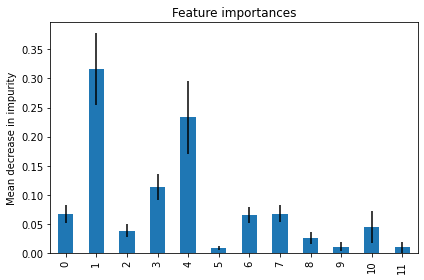

In [504]:
importances = final_forest.feature_importances_
print(importances)
forest_importances = pd.Series(importances)
print(forest_importances)

fig, ax = plt.subplots()
forest_importances.plot.bar(yerr=std, ax=ax)
ax.set_title("Feature importances")
ax.set_ylabel("Mean decrease in impurity")
fig.tight_layout()

<div class="alert alert-block alert-info">
<b>Совет[2]:</b> Можно еще отсоритровать график и добавить цветовую палитру - будет красиво. А также на оси отобразить имена факторов, а то ничего не понятно.

</div>



<div class="alert alert-block alert-success">
<b>Успех:</b>  С тестированием все в порядке! 
</div> 


<div class="alert alert-block alert-info">
<b>Совет:</b> Для понимания, а какие в итоге факторы важны при моделировании, можно выводить их важность, использую feature_importances_, ну и график заодно. Это будет смотреться очнь здорово: результативная метрика и график важности факторов)))<br> Очень ВАЖНАЯ для аналитики штука. Ведь нам не просто модель с метрикой нужна, а ещё и причины понять высокой/низкой метрики. Т.е. понять с какой силой сами факторы влияют на целевую.
    


</div>



## Чек-лист готовности проекта

Поставьте 'x' в выполненных пунктах. Далее нажмите Shift+Enter.

- [x]  Jupyter Notebook открыт
- [ ]  Весь код выполняется без ошибок
- [ ]  Ячейки с кодом расположены в порядке исполнения
- [ ]  Выполнен шаг 1: данные подготовлены
- [ ]  Выполнен шаг 2: задача исследована
    - [ ]  Исследован баланс классов
    - [ ]  Изучены модели без учёта дисбаланса
    - [ ]  Написаны выводы по результатам исследования
- [ ]  Выполнен шаг 3: учтён дисбаланс
    - [ ]  Применено несколько способов борьбы с дисбалансом
    - [ ]  Написаны выводы по результатам исследования
- [ ]  Выполнен шаг 4: проведено тестирование
- [ ]  Удалось достичь *F1*-меры не менее 0.59
- [ ]  Исследована метрика *AUC-ROC*

Вывод

При оптимальных гиперпараметрах и предварительной обработке данных, их уравновешивании и балансировании случайный лес является подходящей моделбю для прогнозирования поведения клиентов банка.